<h1 style="color:#237227;">E-Commerce Customer Churn Analysis</h1>
<hr style="border: 2px solid #237227;">

<h2 style="color:#519A66;">1. Import Libraries</h2>
<hr style="border: 2px solid #519A66;">

In [175]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statistics

%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from PIL import Image, ImageDraw

<h2 style="color:#519A66;">2. Upload Data</h2>
<hr style="border: 2px solid #519A66;">


<h3 style="color:#519A66;"> Load the Dataset</h3>

In [176]:
df = pd.read_csv("customer churn.csv")

<h2 style="color:#519A66;">3. Data Understanding</h2>
<hr style="border: 2px solid #519A66;">

<h3 style="color:#519A66;">Step 1: Display the Dataset</h3>

In [177]:
df.head()

,Customer_ID,Gender,Region,Subscription_Plan,Payment_Method,Age,Days_Since_Last_Login,Customer_Service_Calls,Monthly_Spend,Churn
0,10001,Male,East,Basic,PayPal,27.0,27,1,61.08,0
1,10002,Unknown,West,Pro,PayPal,55.0,146,2,73.09,0
2,10003,Female,West,Pro,E-Wallet,NaN,147,2,116.30,1
3,10004,Female,south,Basic,Credit Card,NaN,34,1,0.58,1
4,10005,Male,North,Basic,Crypto,30.0,146,3,46.35,1


<h3 style="color:#519A66;">Step 2: Check Dataset Dimensions</h3>

In [178]:
df.shape

(10300, 10)

<h3 style="color:#519A66;">Step 3: Check Data Types</h3>

In [179]:
df.dtypes

Customer_ID                 int64
Gender                     object
Region                     object
Subscription_Plan          object
Payment_Method             object
Age                       float64
Days_Since_Last_Login       int64
Customer_Service_Calls      int64
Monthly_Spend             float64
Churn                       int64
dtype: object

<h3 style="color:#519A66;">Step 4: Check Dataset Information</h3>

In [180]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10300 entries, 0 to 10299
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer_ID             10300 non-null  int64  
 1   Gender                  10300 non-null  object 
 2   Region                  10300 non-null  object 
 3   Subscription_Plan       10300 non-null  object 
 4   Payment_Method          9575 non-null   object 
 5   Age                     9267 non-null   float64
 6   Days_Since_Last_Login   10300 non-null  int64  
 7   Customer_Service_Calls  10300 non-null  int64  
 8   Monthly_Spend           9786 non-null   float64
 9   Churn                   10300 non-null  int64  
dtypes: float64(2), int64(4), object(4)
memory usage: 804.8+ KB


In [181]:
# Missing values (Payment_Method, Age, Monthly_Spend) 

<h3 style="color:#519A66;">Step 5: Check Unique Values</h3>

In [182]:
df.nunique()

Customer_ID               10000
Gender                        4
Region                        8
Subscription_Plan             6
Payment_Method                4
Age                          73
Days_Since_Last_Login       180
Customer_Service_Calls       11
Monthly_Spend              6768
Churn                         2
dtype: int64

<h3 style="color:#519A66;">Step 6: Explore Categorical Variables</h3>

In [183]:
# Check the number of unique values in categorical columns
categorical_columns = [
    'Gender',
    'Region',
    'Subscription_Plan',
    'Payment_Method',
    'Churn'
]
print("\nUnique Values Per Column:")
for col in categorical_columns:
    unique_count = df[col].nunique(dropna = False)
    print(f"   {col}: { unique_count} unique values")


Unique Values Per Column:
   Gender: 4 unique values
   Region: 8 unique values
   Subscription_Plan: 6 unique values
   Payment_Method: 5 unique values
   Churn: 2 unique values


In [184]:
# Display the actual unique values in categorical columns
categorical_columns = [
    'Gender',
    'Region',
    'Subscription_Plan',
    'Payment_Method',
    'Churn'
]
for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].unique())


Gender:
['Male' 'Unknown' 'Female' 'Non-Binary']

Region:
['East' 'West' 'south' 'North' 'South' 'north' 'east' 'west']

Subscription_Plan:
['Basic' 'Pro' 'BASIC' 'PLUS' 'Plus' 'PRO']

Payment_Method:
['PayPal' 'E-Wallet' 'Credit Card' 'Crypto' nan]

Churn:
[0 1]


In [185]:
# Capitalizationin Region & Subscription_Plan

<h3 style="color:#519A66;">Step 7: Generate Descriptive Statistics</h3>

In [186]:
df.describe()

,Customer_ID,Age,Days_Since_Last_Login,Customer_Service_Calls,Monthly_Spend,Churn
count,10300.000000,9267.000000,10300.000000,10300.000000,9786.000000,10300.000000
mean,14859.237864,33.521852,89.449903,1.787379,300.093737,0.762039
std,2959.197492,11.514686,52.088510,1.363470,4733.134612,0.425856
min,10001.000000,-10.000000,0.000000,-1.000000,-10.000000,0.000000
25%,12275.750000,26.000000,44.000000,1.000000,26.275000,1.000000
50%,14850.500000,33.000000,90.000000,2.000000,66.355000,1.000000
75%,17425.250000,40.000000,135.000000,3.000000,115.915000,1.000000
max,20000.000000,150.000000,179.000000,9.000000,99999.990000,1.000000


In [187]:
# Min Age= -10?! / Max Age = 150?! 
# Min Customer_Service_Calls = -1 ?!
# Min Monthly_Spend = -10 ?!   / Large Gap between SD & Mean --> Outlier / Max = 99999.99 ?!

<h2 style="color:#519A66;">4. Data Pre-processing</h2>
<hr style="border: 2px solid #519A66;">

<h3 style="color:#519A66;">Step 1: Create a Copy of the Dataset</h3>

In [188]:
# Create a copy of the original dataset for cleaning
df_work = df.copy()

<h3 style="color:#519A66;">Step 2: Check and Remove Duplicates</h3>

In [189]:
# Check for duplicate rows
duplicates = df.duplicated().sum()
print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 300


In [190]:
# Check whether duplicate Customer IDs have identical records
df[df["Customer_ID"].duplicated(keep = False)].sort_values("Customer_ID").head(10)

,Customer_ID,Gender,Region,Subscription_Plan,Payment_Method,Age,Days_Since_Last_Login,Customer_Service_Calls,Monthly_Spend,Churn
10000,10001,Male,East,Basic,PayPal,27.0,27,1,61.08,0
0,10001,Male,East,Basic,PayPal,27.0,27,1,61.08,0
1,10002,Unknown,West,Pro,PayPal,55.0,146,2,73.09,0
10001,10002,Unknown,West,Pro,PayPal,55.0,146,2,73.09,0
10002,10003,Female,West,Pro,E-Wallet,NaN,147,2,116.30,1
2,10003,Female,West,Pro,E-Wallet,NaN,147,2,116.30,1
3,10004,Female,south,Basic,Credit Card,NaN,34,1,0.58,1
10003,10004,Female,south,Basic,Credit Card,NaN,34,1,0.58,1
10004,10005,Male,North,Basic,Crypto,30.0,146,3,46.35,1
4,10005,Male,North,Basic,Crypto,30.0,146,3,46.35,1


In [191]:
# Remove duplicate rows
df_work= df_work.drop_duplicates().reset_index(drop=True) #Resets DataFrame index after removing duplicate rows

# Check again
print("After removing duplicates:", df_work.duplicated().sum())

After removing duplicates: 0


In [192]:
# Check new dataset shape
print("New dataset shape:",df_work.shape)

New dataset shape: (10000, 10)


<h3 style="color:#519A66;">Step 4: Standardize Categorical Values</h3>

<h4 style="color:#519A66;">Standardize Region Capitalization</h4>

In [193]:
# Standardize Region capitalization
df_work['Region'] = df_work['Region'].str.title()

# Check the result
print(df_work['Region'].value_counts())

Region
South    2534
East     2509
West     2503
North    2454
Name: count, dtype: int64


In [194]:
# Check the standardized values
print("\nRegion:", df_work["Region"].unique())


Region: ['East' 'West' 'South' 'North']


<h4 style="color:#519A66;">Standardize Subscription Plan Capitalization</h4>

In [195]:
df_work['Subscription_Plan'] = df_work['Subscription_Plan'].str.title()
print(df_work['Subscription_Plan'].value_counts())

Subscription_Plan
Basic    4851
Pro      3125
Plus     2024
Name: count, dtype: int64


In [196]:
# Check the standardized values
print("\nSubscription_Plan:", df_work["Subscription_Plan"].unique())


Subscription_Plan: ['Basic' 'Pro' 'Plus']


<h3 style="color:#519A66;">Step 3: Handle Missing and Invalid Values</h3>

In [197]:
# Check missing values
missing_values = df_work.isnull().sum()
print(missing_values)

Customer_ID                 0
Gender                      0
Region                      0
Subscription_Plan           0
Payment_Method            700
Age                       995
Days_Since_Last_Login       0
Customer_Service_Calls      0
Monthly_Spend             500
Churn                       0
dtype: int64


<h4 style="color:#519A66;">Handling Missing Payment Method</h4>

#### Three approaches were considered to handle these missing values:

1. Replace missing values with "Unknown".
2. Use grouping based on Subscription_Plan and Age_Group.
3. Use a Random Forest classifier to predict Payment_Method.

The three approaches were compared using the known Payment_Method values.

In [198]:
# Replace missing payment methods with "Unknown" or "Mode"
df_work['Payment_Method'] = df_work['Payment_Method'].fillna('Unknown')

In [199]:
print(df_work['Payment_Method'].value_counts())

Payment_Method
Crypto         2365
PayPal         2324
Credit Card    2310
E-Wallet       2301
Unknown         700
Name: count, dtype: int64


<h4 style="color:#519A66;">Method 2: uses Subscription_Plan and Age_Group to identify the most common Payment_Method within each group. </h4

##### The second approach uses Subscription_Plan and Age_Group to identify the most common Payment_Method within each group.The known Payment_Method values are divided into training and testing data to evaluate the accuracy of this approach.

In [114]:
# Create a separate dataset for Payment Method comparison

payment_df = df.copy()

# Remove duplicate rows
payment_df = payment_df.drop_duplicates().reset_index(drop=True)

# Standardize Subscription Plan
payment_df['Subscription_Plan'] = payment_df['Subscription_Plan'].str.title()

# Clean Age
payment_df.loc[
    (payment_df['Age'] < 18) | (payment_df['Age'] > 100),
    'Age'
] = np.nan

# Fill missing Age with median
payment_df['Age'] = payment_df['Age'].fillna(
    payment_df['Age'].median()
)

# Create Age Groups
payment_df['Age_Group'] = pd.cut(
    payment_df['Age'],
    bins=[17, 25, 35, 45, 55, 100],
    labels=['18-25', '26-35', '36-45', '46-55', '56+']
)

print(
    "Missing Payment_Method values:",
    payment_df['Payment_Method'].isnull().sum()
)

Missing Payment_Method values: 700


In [115]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Use only rows where Payment_Method is known
known_payment = payment_df[
    payment_df['Payment_Method'].notna()
].copy()

# Split the data
train_group, test_group = train_test_split(
    known_payment,
    test_size=0.20,
    random_state=42,
    stratify=known_payment['Payment_Method']
)

# Find the most common Payment_Method in each group
group_mode = (
    train_group
    .groupby(
        ['Subscription_Plan', 'Age_Group'],
        observed=True
    )['Payment_Method']
    .agg(lambda x: x.mode().iloc[0])
)

# Overall mode as a fallback
overall_mode = train_group[
    'Payment_Method'
].mode().iloc[0]

# Predict Payment_Method
group_predictions = []

for _, row in test_group.iterrows():

    key = (
        row['Subscription_Plan'],
        row['Age_Group']
    )

    if key in group_mode.index:
        prediction = group_mode.loc[key]
    else:
        prediction = overall_mode

    group_predictions.append(prediction)

# Calculate accuracy
group_accuracy = accuracy_score(
    test_group['Payment_Method'],
    group_predictions
)

print(f"Grouping Accuracy: {group_accuracy:.2%}")

Grouping Accuracy: 24.14%


##### There are four payment methods in the dataset.This indicates that Subscription_Plan and Age_Group do not provide enough information to reliably determine Payment_Method.

<h4 style="color:#519A66;">Method 3:  Random Forest </h4>

##### The third approach uses a Random Forest classifier to predict Payment_Method.The model uses multiple customer attributes including Age, Subscription_Plan, Gender, Region, Days_Since_Last_Login, Customer_Service_Calls, and Monthly_Spend.The model is evaluated using Payment_Method values that are already known.

In [116]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Features used to predict Payment_Method

features = [
    'Age',
    'Subscription_Plan',
    'Gender',
    'Region',
    'Days_Since_Last_Login',
    'Customer_Service_Calls',
    'Monthly_Spend'
]

categorical_features = [
    'Subscription_Plan',
    'Gender',
    'Region'
]

numerical_features = [
    'Age',
    'Days_Since_Last_Login',
    'Customer_Service_Calls',
    'Monthly_Spend'
]

# Features and target
X = known_payment[features]
y = known_payment['Payment_Method']

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Encode categorical variables
preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numerical',
            'passthrough',
            numerical_features
        )
    ]
)

# Create Random Forest pipeline
rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'classifier',
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1,
                class_weight='balanced'
            )
        )
    ]
)

# Train model
rf_model.fit(X_train, y_train)

# Predict
rf_predictions = rf_model.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

print(f"Random Forest Accuracy: {rf_accuracy:.2%}")

Random Forest Accuracy: 24.30%


##### The model used several customer attributes, but the prediction accuracy remained close to the expected accuracy when choosing among four payment methods.This indicates that the available features do not provide enough predictive information to reliably determine Payment_Method.

<h4 style="color:#519A66;">Comparison of Payment Method Imputation Methods</h4>

In [117]:
comparison = pd.DataFrame({
    'Method': [
        'Unknown',
        'Grouping',
        'Random Forest'
    ],
    'Accuracy': [
        np.nan,
        group_accuracy,
        rf_accuracy
    ]
})

comparison

,Method,Accuracy
0,Unknown,NaN
1,Grouping,0.241398
2,Random Forest,0.243011


##### This indicates that the available variables do not provide a strong relationship with Payment_Method.Therefore, predicting the missing values may introduce incorrect information.The missing Payment_Method values will be kept as "Unknown".

<h4 style="color:#519A66;">Handling Missing Monthly Spend</h4>

In [118]:
df_work.groupby('Region')['Monthly_Spend'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
Region,,,,
East,2380,157.554777,64.430,2896.715063
North,2324,205.463167,67.835,3589.086719
South,2423,117.474639,65.790,2030.881418
West,2373,286.555735,67.320,4583.273036


In [119]:
df_work.groupby('Gender')['Monthly_Spend'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
Gender,,,,
Female,3786,180.417528,65.460,3247.245101
Male,3855,231.335821,66.370,3940.061672
Non-Binary,942,75.593121,67.935,57.897274
Unknown,917,186.527274,68.250,3300.278476


In [120]:
df_work.groupby('Subscription_Plan')['Monthly_Spend'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
Subscription_Plan,,,,
Basic,4611,165.055830,29.52,3604.192860
Plus,1925,262.586057,159.48,3217.596415
Pro,2964,185.750334,84.78,3177.903598


In [121]:
df_work.loc[(df_work['Monthly_Spend'] < 0) | (df_work['Monthly_Spend'] > 312), 'Monthly_Spend'] = np.nan

In [122]:
# Monthly_Spend → use Subscription Plan groups
df_work['Monthly_Spend'] = (
    df_work.groupby('Subscription_Plan')['Monthly_Spend']
    .transform(lambda x: x.fillna(x.median()))
)

# Fallback
df_work['Monthly_Spend'] = df_work['Monthly_Spend'].fillna(
    df_work['Monthly_Spend'].median()
)
print("Missing Monthly Spend after imputation:",df_work['Monthly_Spend'].isnull().sum())

Missing Monthly Spend after imputation: 0


In [123]:
print(df_work['Monthly_Spend'].describe())

count    10000.000000
mean        75.834323
std         59.052888
min          0.000000
25%         29.407500
50%         66.775000
75%        115.075000
max        311.390000
Name: Monthly_Spend, dtype: float64


###### <h4 style="color:#519A66;">Handling Missing and Invalid Ages</h4>

In [124]:
# Treat ages below 18 and above 100 as invalid
df_work.loc[(df_work['Age'] < 18) | (df_work['Age'] > 70), 'Age'] = np.nan

In [125]:
df_work.groupby('Gender')['Age'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
Gender,,,,
Female,3381,34.595682,34.0,9.066524
Male,3447,34.560487,34.0,8.893207
Non-Binary,838,34.330549,34.0,8.927522
Unknown,825,34.676364,34.0,8.984790


In [126]:
df_work.groupby('Region')['Age'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
Region,,,,
East,2124,34.514595,34.0,8.874181
North,2106,34.384141,34.0,8.884111
South,2135,34.851522,35.0,9.010562
West,2126,34.499059,34.0,9.121958


In [127]:
df_work.groupby('Subscription_Plan')['Age'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
Subscription_Plan,,,,
Basic,4131,34.529896,34.0,8.927107
Plus,1711,34.493863,34.0,9.137023
Pro,2649,34.659494,34.0,8.942179


### Comparison of Age Imputation Methods

Random Forest Regression was tested as a machine learning approach
for predicting missing Age values and compared with median imputation.

Lower MAE and RMSE indicate better performance.

In [128]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Use rows where Age is available
data = df_work[df_work['Age'].notna()].copy()

features = [
    'Monthly_Spend',
    'Days_Since_Last_Login',
    'Customer_Service_Calls'
]

X = data[features]
y = data['Age']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

pred = model.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))

print(f"Random Forest MAE: {mae:.2f}")
print(f"Random Forest RMSE: {rmse:.2f}")

Random Forest MAE: 7.67
Random Forest RMSE: 9.50


In [129]:
median_age = y_train.median()

median_pred = np.full(len(y_test), median_age)

median_mae = mean_absolute_error(y_test, median_pred)
median_rmse = np.sqrt(mean_squared_error(y_test, median_pred))

print(f"Median MAE: {median_mae:.2f}")
print(f"Median RMSE: {median_rmse:.2f}")

Median MAE: 7.15
Median RMSE: 8.89


### Conclusion

Median imputation achieved lower MAE and RMSE than Random Forest.
Therefore, median imputation was selected for handling missing Age values
in the final dataset.

In [130]:
# Fallback for any group with no available median
df_work['Age'] = df_work['Age'].fillna(df_work['Age'].median())

In [131]:
print("Missing Age values after imputation:",df_work['Age'].isnull().sum())

Missing Age values after imputation: 0


In [132]:
print(df_work['Age'].describe())

count    10000.00000
mean        34.47810
std          8.27131
min         18.00000
25%         29.00000
50%         34.00000
75%         39.00000
max         70.00000
Name: Age, dtype: float64


<h4 style="color:#519A66;">Handling Customer Service Calls Below Zero</h4>

In [133]:
# Replace all negative values with NaN
df_work.loc[df_work['Customer_Service_Calls'] < 0, 'Customer_Service_Calls'] = np.nan

# Fill missing values with the median
df_work['Customer_Service_Calls'] = df_work['Customer_Service_Calls'].fillna(
    df_work['Customer_Service_Calls'].median()
)

In [134]:
print(df_work['Customer_Service_Calls'].describe())

count    10000.000000
mean         1.806000
std          1.349943
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max          9.000000
Name: Customer_Service_Calls, dtype: float64


In [135]:
df_work.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer_ID             10000 non-null  int64  
 1   Gender                  10000 non-null  object 
 2   Region                  10000 non-null  object 
 3   Subscription_Plan       10000 non-null  object 
 4   Payment_Method          10000 non-null  object 
 5   Age                     10000 non-null  float64
 6   Days_Since_Last_Login   10000 non-null  int64  
 7   Customer_Service_Calls  10000 non-null  float64
 8   Monthly_Spend           10000 non-null  float64
 9   Churn                   10000 non-null  int64  
dtypes: float64(3), int64(3), object(4)
memory usage: 781.4+ KB


<h3 style="color:#519A66;">Step 5: Save the Cleaned Dataset</h3>

In [136]:
# Export the cleaned dataset for reuse 
df_work.to_csv('cleaned_customer_churn.csv', index=False)
print("Saved_cleaned_customer_churn.csv", df_work.shape[0], "rows,", df_work.shape[1], "columns")

Saved_cleaned_customer_churn.csv 10000 rows, 10 columns


<h2 style="color:#519A66;">5. Descriptive and Inferential Statistics</h2>
<hr style="border: 2px solid #519A66;">

In [137]:
df_work.describe()

,Customer_ID,Age,Days_Since_Last_Login,Customer_Service_Calls,Monthly_Spend,Churn
count,10000.00000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000
mean,15000.50000,34.47810,89.368500,1.806000,75.834323,0.763400
std,2886.89568,8.27131,52.135828,1.349943,59.052888,0.425016
min,10001.00000,18.00000,0.000000,0.000000,0.000000,0.000000
25%,12500.75000,29.00000,44.000000,1.000000,29.407500,1.000000
50%,15000.50000,34.00000,90.000000,2.000000,66.775000,1.000000
75%,17500.25000,39.00000,135.000000,3.000000,115.075000,1.000000
max,20000.00000,70.00000,179.000000,9.000000,311.390000,1.000000


<h3 style="color:#519A66;"> Correlation Analysis</h3>

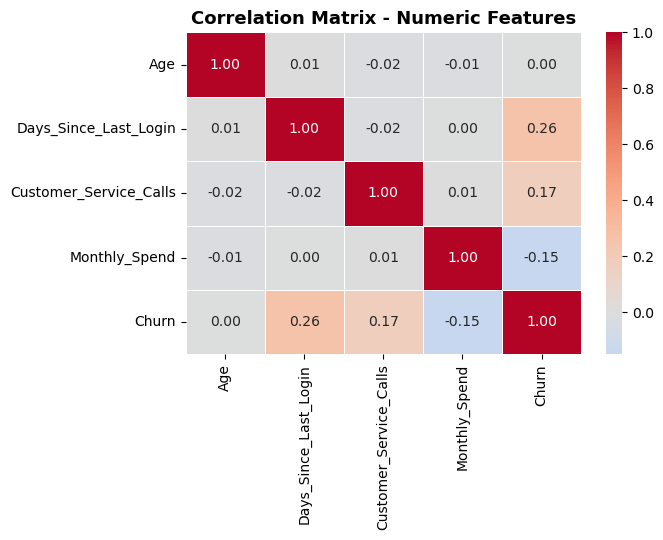

In [138]:
numeric_cols = ['Age', 'Days_Since_Last_Login', 'Customer_Service_Calls', 'Monthly_Spend', 'Churn']
corr_matrix = df_work[numeric_cols].corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, linecolor='white')
plt.title('Correlation Matrix - Numeric Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [139]:
# Days_Since_Last_Login shows the strongest positive correlation with Churn (0.26),
# suggesting that customers who have been inactive for longer periods are more likely to churn.

# Customer_Service_Calls have a weak positive correlation with Churn (0.17),
# which may indicate that customers who contact customer service more frequently
# are slightly more likely to leave.

# Monthly_Spend has a weak negative correlation with Churn (-0.15),
# suggesting that customers with higher monthly spending are slightly less likely to churn.

# Age has almost no correlation with Churn (0.00),
# indicating that age does not appear to have a meaningful linear relationship with churn.

# Overall, the correlations are relatively weak, meaning that Churn is not strongly
# explained by any single numeric feature and may be influenced by multiple factors.

<h3 style="color:#519A66;"> T-Tests: Numeric Features vs Churn</h3>

In [140]:
from scipy import stats

# --- T-tests: numeric features vs Churn (0 = retained, 1 = churned) ---
numeric_features = ['Age', 'Days_Since_Last_Login', 'Customer_Service_Calls', 'Monthly_Spend']

print("T-TEST RESULTS (Retained vs Churned)")
print("=" * 55)
for feature in numeric_features:
    retained = df_work[df_work['Churn'] == 0][feature]
    churned = df_work[df_work['Churn'] == 1][feature]
    t_stat, p_val = stats.ttest_ind(retained, churned, equal_var=False)
    significance = "Significant (p < 0.05)" if p_val < 0.05 else "Not significant"
    print(f"{feature:28s} t = {t_stat:7.3f}   p = {p_val:.4f}   -> {significance}")


T-TEST RESULTS (Retained vs Churned)
Age                          t =  -0.118   p = 0.9058   -> Not significant
Days_Since_Last_Login        t = -28.681   p = 0.0000   -> Significant (p < 0.05)
Customer_Service_Calls       t = -18.641   p = 0.0000   -> Significant (p < 0.05)
Monthly_Spend                t =  14.596   p = 0.0000   -> Significant (p < 0.05)


In [141]:
#Note: A p-value shown as 0.0000 does not mean that the p-value is exactly zero
#It means that the p-value is extremely small and was rounded to 0.0000 when displayed.

In [142]:
# The t-tests confirm Days_Since_Last_Login and Monthly_Spend differ significantly
# between churned and retained customers, backing up the visual patterns from the EDA section. 

<h3 style="color:#519A66;">Chi-Square Tests: Categorical Features vs Churn</h3>

In [143]:
# --- Chi-square tests: categorical features vs Churn ---
categorical_features = ['Gender', 'Region', 'Subscription_Plan', 'Payment_Method']

print("CHI-SQUARE TEST RESULTS")
print("=" * 55)
for feature in categorical_features:
    contingency = pd.crosstab(df_work[feature], df_work['Churn'])
    chi2, p_val, dof, expected = stats.chi2_contingency(contingency)
    significance = "Significant (p < 0.05)" if p_val < 0.05 else "Not significant"
    print(f"{feature:28s} chi2 = {chi2:7.3f}   p = {p_val:.4f}   -> {significance}")


CHI-SQUARE TEST RESULTS
Gender                       chi2 =   0.962   p = 0.8105   -> Not significant
Region                       chi2 =  36.849   p = 0.0000   -> Significant (p < 0.05)
Subscription_Plan            chi2 = 150.483   p = 0.0000   -> Significant (p < 0.05)
Payment_Method               chi2 =   6.814   p = 0.1460   -> Not significant


In [144]:
 #The chi-square tests confirm Subscription_Plan and Region have a statistically significant relationship with churn,
#while Payment_Method and Gender do not - matching the "weak relationship". 

<h2 style="color:#519A66;">6. Exploratory Data Analysis(EDA)</h2>
<hr style="border: 2px solid #519A66;">

<h3 style="color:#519A66;">Step 1: Analyze Churn Distribution</h3>

In [145]:
# Churn Distribution
print(df_work['Churn'].value_counts())

print("\nChurn Percentage:")
print(df_work['Churn'].value_counts(normalize=True) * 100)

Churn
1    7634
0    2366
Name: count, dtype: int64

Churn Percentage:
Churn
1    76.34
0    23.66
Name: proportion, dtype: float64


<h3 style="color:#519A66;">Step 2: Feature Engineering</h3>

### login_Segmentation

In [146]:
df_work['Login_Activity'] = pd.cut(
    df_work['Days_Since_Last_Login'],
    bins=[-1, 30, 90, float('inf')], #inf = infinity
    labels=['Active', 'At Risk', 'Inactive']
)

print(df_work['Login_Activity'].value_counts())

Login_Activity
Inactive    4956
At Risk     3292
Active      1752
Name: count, dtype: int64


### Age_Grouping

In [147]:
df_work['Age_Group'] = pd.cut(
    df_work['Age'],
    bins=[17, 24, 34, 49, float('inf')], 
    labels=['Young', 'Adult', 'Middle-Aged', 'Senior']
)

print(df_work['Age_Group'].value_counts())

Age_Group
Adult          4666
Middle-Aged    3622
Young          1219
Senior          493
Name: count, dtype: int64


<h3 style="color:#CC3A63;">What does the customer base split look like: churned vs retained?</h3>

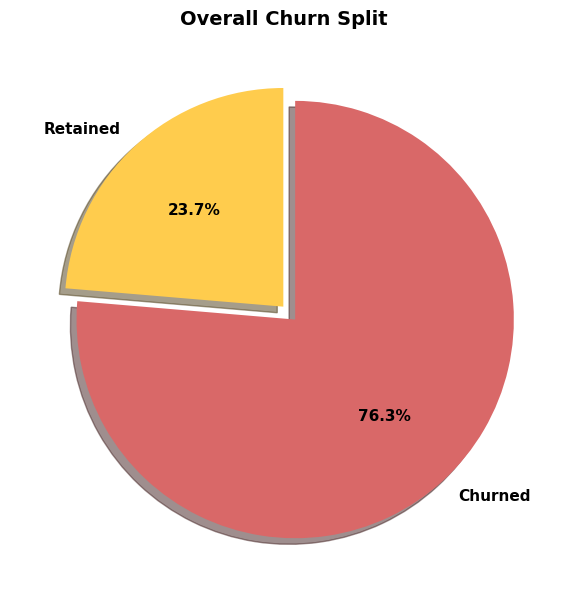

In [148]:
churn_counts = df_work['Churn'].value_counts().sort_index()

labels = ['Retained', 'Churned']
colors = ['#FFCC4D', '#D96868']

# Pull out the larger slice
explode = [
    0.08 if v == churn_counts.max() else 0
    for v in churn_counts.values
]

plt.figure(figsize=(6, 6))

wedges, texts, autotexts = plt.pie(
    churn_counts.values,
    labels=labels,
    autopct='%1.1f%%',
    colors=colors,
    startangle=90,
    explode=explode,
    shadow=True,
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)

plt.title('Overall Churn Split', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [149]:
# 76.3% of the 10,000 customers in this dataset have churned, versus 23.7% retained.
# That's a heavily imbalanced base

<h3 style="color:#CC3A63;">Does customer activity level affect churn ?</h3>

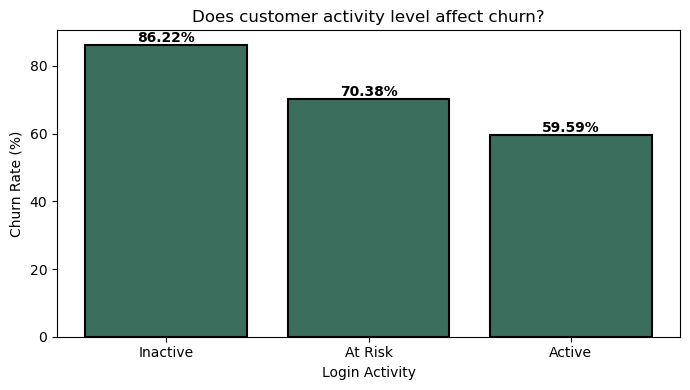

In [150]:
churn_by_activity_level = (
    df_work.groupby('Login_Activity')['Churn']
      .mean()
      .mul(100)
      .round(2)
      .sort_values(ascending=False)
)

plt.figure(figsize=(7, 4))

bars = plt.bar(
    churn_by_activity_level.index,
    churn_by_activity_level.values,
    color='#3C6E5E',
    edgecolor='black',
    linewidth=1.5
)

# Add value labels above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{height:.2f}%',
        ha='center',
        va='bottom',
        fontweight='bold'
    )

plt.title('Does customer activity level affect churn?')
plt.xlabel('Login Activity')
plt.ylabel('Churn Rate (%)')

plt.tight_layout()
plt.show()

In [151]:
# clear positive relationship bet inactive & churn
# Less active customers are more likely to churn


<h3 style="color:#CC3A63;"> Is churn concentrated in a particular age group?</h3>

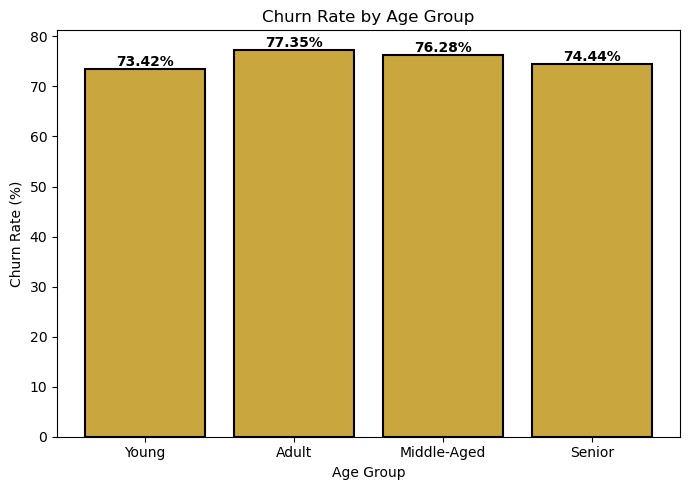

In [152]:
churn_by_age = (
    df_work.groupby('Age_Group', observed=True)['Churn']
      .mean()
      .mul(100)
      .round(2)
)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    churn_by_age.index.astype(str),
    churn_by_age.values,
    color='#C9A63E',
    edgecolor='black',
    linewidth=1.5
)

# Add value labels above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height ,
        f'{height:.2f}%',
        ha='center',
        va='bottom',
        fontweight='bold'
    )

plt.title('Churn Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Churn Rate (%)')

plt.tight_layout()
plt.show()

In [153]:
# Churn rates are relatively similar across all age groups.
# Adult customers have the highest churn rate, while Young customers have the lowest.
# Overall, Age Group does not show a strong difference in churn rates.
# This suggests that age may not be a major factor influencing customer churn.

<h3 style="color:#CC3A63;">Does time since last login matter, or is it a cliff?</h3>

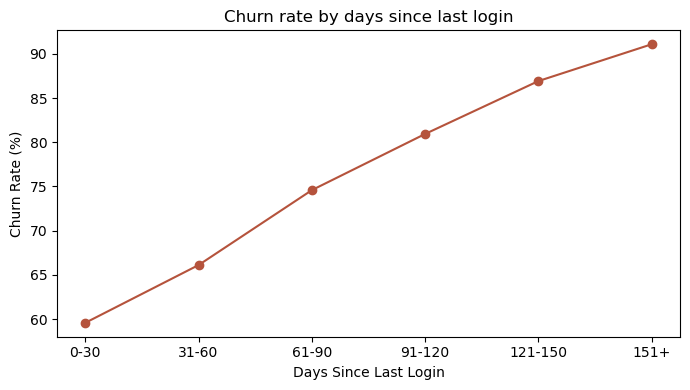

In [154]:
bins = [-1, 30, 60, 90, 120, 150, 200]
labels = ['0-30', '31-60', '61-90', '91-120', '121-150', '151+']
df_work['days_bucket'] = pd.cut(df_work['Days_Since_Last_Login'], bins=bins, labels=labels)

churn_by_days = (
    df_work.groupby('days_bucket', observed=True)['Churn']
      .mean()
      .mul(100)
      .round(2)
)

plt.figure(figsize=(7, 4))
plt.plot(churn_by_days.index, churn_by_days.values, marker='o', color='#B5533C')
plt.title('Churn rate by days since last login')
plt.xlabel('Days Since Last Login')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()

In [155]:
# clear positive Relationship between login inactivity and churn.

<h3 style="color:#CC3A63;">Does payment method affect customer churn?</h3>

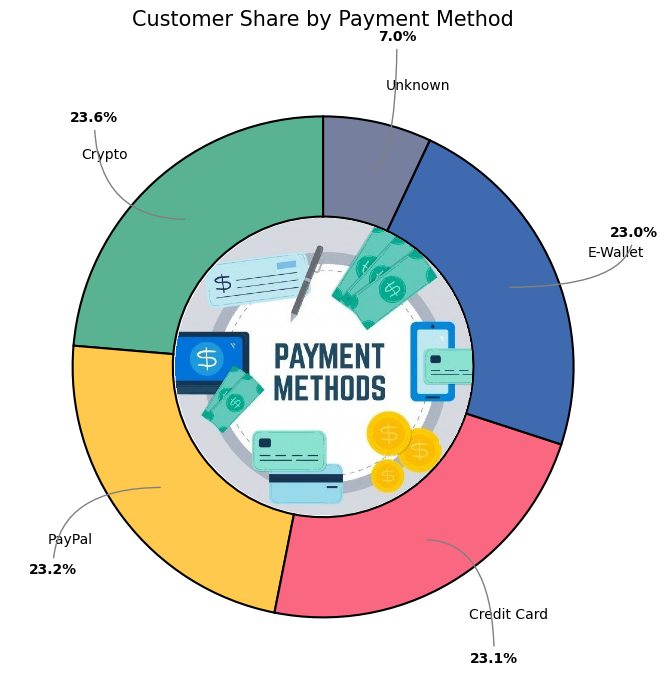

In [156]:
# 1. Count Payment Methods
payment_counts = df_work['Payment_Method'].value_counts()

fig, ax = plt.subplots(figsize=(7, 7))

wedges, texts = ax.pie(
    payment_counts.values,
    labels=payment_counts.index,
    startangle=90,

    colors=[
        '#59B292',
        '#FFC94D',
        '#FA6781',
        '#406AAF',
        '#767F9E'
    ],

    wedgeprops={
        'width': 0.4,
        'edgecolor': 'black',
        'linewidth': 1.5
    },

    labeldistance=1.15
)

# 4. Add Percentages Outside Donut
total = payment_counts.sum()

for wedge, value in zip(wedges, payment_counts.values):

    # Calculate percentage
    percentage = value / total * 100

    # Find middle angle of each slice
    angle = (wedge.theta1 + wedge.theta2) / 2

    # Convert angle to radians
    angle_rad = np.deg2rad(angle)

    # Coordinates on donut
    x = np.cos(angle_rad)
    y = np.sin(angle_rad)

    # Add percentage outside
    ax.annotate(
        f'{percentage:.1f}%',

        xy=(x * 0.8, y * 0.8),

        xytext=(x * 1.35, y * 1.35),

        ha='center',
        va='center',

        fontsize=10,
        fontweight='bold',

        arrowprops=dict(
            arrowstyle='-',
            connectionstyle='angle3',
            color='gray'
        )
    )

# 5. Load Payment Methods Image (optional - skip gracefully if the file isn't available)
try:
    logo = Image.open('payment-methods.jpg').convert('RGBA')

    # 6. Crop Image to Square
    size = min(logo.size)
    left = (logo.width - size) // 2
    top = (logo.height - size) // 2
    logo = logo.crop((left, top, left + size, top + size))

    # 7. Make Image Circular
    mask = Image.new('L', logo.size, 0)
    draw = ImageDraw.Draw(mask)
    draw.ellipse((0, 0, logo.width, logo.height), fill=255)
    logo.putalpha(mask)

    # 8. Convert Image to NumPy
    logo_array = np.array(logo)

    # 9. Put Image in Donut Center
    imagebox = OffsetImage(logo_array, zoom=0.43)
    ab = AnnotationBbox(imagebox, (0, 0), frameon=False, box_alignment=(0.5, 0.5))
    ax.add_artist(ab)
except FileNotFoundError:
    # logo file not available - donut chart still renders fine without it
    pass

# 10. Title
ax.set_title(
    'Customer Share by Payment Method',
    fontsize=15,
    pad=20
)

ax.set_aspect('equal')

plt.tight_layout()

plt.show()


In [157]:
# Churn rates are very similar across payment methods,
# small difference between the highest and lowest rates
# weak relationship between payment method and churn.

<h3 style="color:#CC3A63;">Which subscription plan has the highest churn rate?</h3>

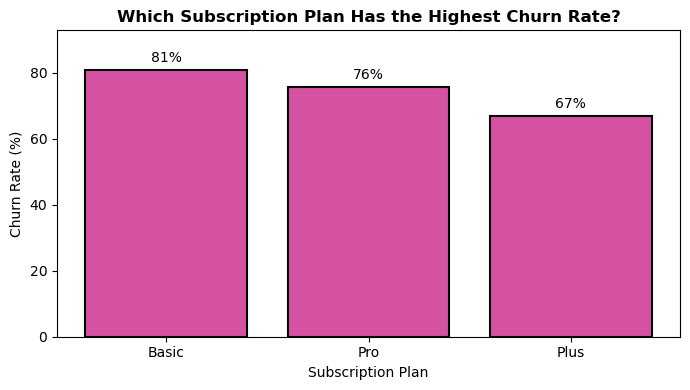

In [158]:


churn_by_plan = (
    df_work.groupby('Subscription_Plan')['Churn']
      .mean()
      .mul(100)
      .round(2)
      .sort_values(ascending=False)
)

plt.figure(figsize=(7, 4))
bars = plt.bar(churn_by_plan.index, churn_by_plan.values, color='#D552A3',
                edgecolor='black',
                linewidth=1.5)

# Add value labels above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + (height * 0.02),
        f'{height:.0f}%',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title('Which Subscription Plan Has the Highest Churn Rate?', fontsize=12, fontweight='bold')
plt.xlabel('Subscription Plan')
plt.ylabel('Churn Rate (%)')

plt.ylim(0, max(churn_by_plan.values) * 1.15)
plt.tight_layout()
plt.show()

In [159]:
# The Basic plan has the highest churn rate at 80%, while the Plus plan has the lowest at 67%
# customers on the Basic plan are more likely to churn compared with customers on the other subscription plans

<h3 style="color:#CC3A63;">Do customers with more customer service calls churn more?</h3>

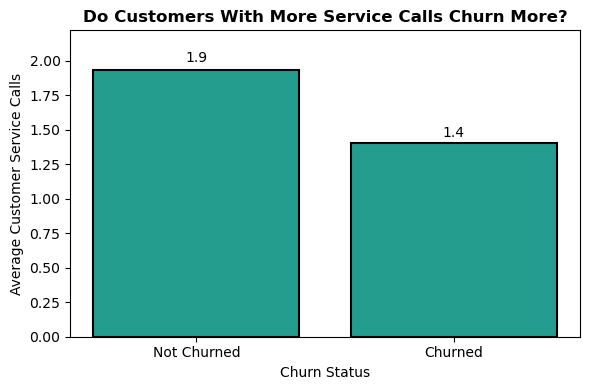

In [160]:
calls_by_churn = (
    df_work.groupby('Churn')['Customer_Service_Calls']
      .mean()
      .round(2)
      .sort_values(ascending=False)
)

plt.figure(figsize=(6, 4))
bars = plt.bar(
    ['Not Churned', 'Churned'],
    calls_by_churn.values,
    color='#249D8F',
    edgecolor='black',
    linewidth=1.5
)

# Add value labels above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + (height * 0.02),
        f'{height:.1f}',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title('Do Customers With More Service Calls Churn More?', fontsize=12, fontweight='bold')
plt.xlabel('Churn Status')
plt.ylabel('Average Customer Service Calls')

plt.ylim(0, max(calls_by_churn.values) * 1.15)
plt.tight_layout()
plt.show()

In [161]:
# Non Churned customers have a higher average number of customer service calls (1.9) than churned customers (1.4)
# positive relationship between service calls and churn

<h3 style="color:#CC3A63;">Does monthly spending differ between churned and non-churned customers?</h3>

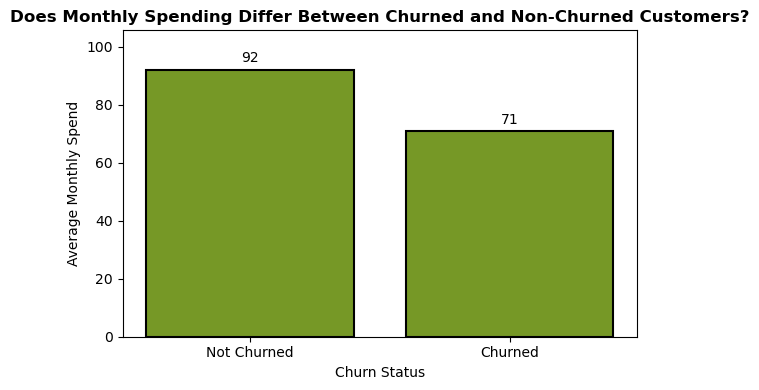

In [162]:
spend_by_churn = (
    df_work.groupby('Churn')['Monthly_Spend']
      .mean()
      .round(2)
)

plt.figure(figsize=(6, 4))

bars = plt.bar(
    ['Not Churned', 'Churned'],
    spend_by_churn.values,
    color='#769826',
    edgecolor='black',
    linewidth=1.5
)

# Add value labels above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + (height * 0.02),
        f'{height:,.0f}',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title('Does Monthly Spending Differ Between Churned and Non-Churned Customers?',
          fontsize=12, fontweight='bold')
plt.xlabel('Churn Status')
plt.ylabel('Average Monthly Spend')

# Give headroom above the tallest bar so labels don't get clipped
plt.ylim(0, max(spend_by_churn.values) * 1.15)

plt.tight_layout()
plt.show()

In [163]:
# Churned customers have a lower average monthly spend (71) than non-churned customers (91)
# negative relationship between monthly spending and churn.

<h3 style="color:#CC3A63;">Does churn rate differ by gender?</h3>

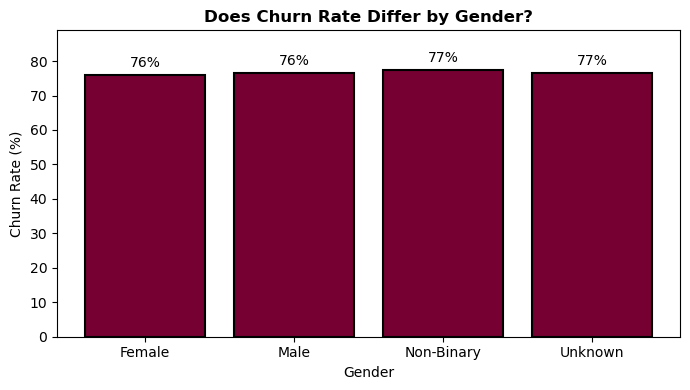

In [164]:
churn_by_gender = (
    df_work.groupby('Gender')['Churn']
      .mean()
      .mul(100)
      .round(2)
)

plt.figure(figsize=(7, 4))
bars = plt.bar(churn_by_gender.index, churn_by_gender.values,color = '#760031',
                edgecolor='black',
                linewidth=1.5)

# Add value labels above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + (height * 0.02),
        f'{height:.0f}%',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title('Does Churn Rate Differ by Gender?', fontsize=12, fontweight='bold')
plt.xlabel('Gender')
plt.ylabel('Churn Rate (%)')

# Add headroom so top labels don't get clipped
plt.ylim(0, max(churn_by_gender.values) * 1.15)

plt.tight_layout()
plt.show()

In [165]:
# Churn rate appears to be very similar across genders, gender not have a strong relationship with customer churn

<h3 style="color:#CC3A63;">Which region has the highest churn rate?</h3>

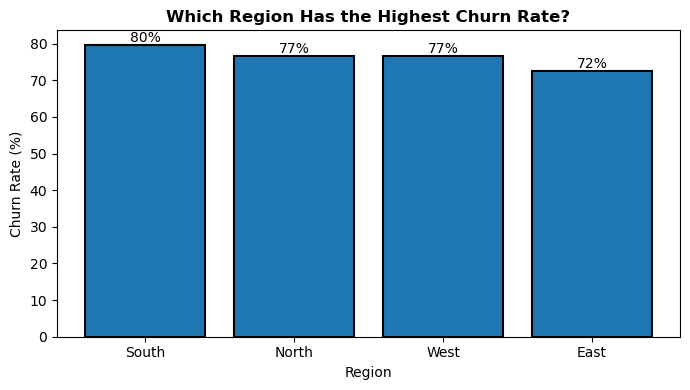

In [166]:
churn_by_region = (
    df_work.groupby('Region')['Churn']
      .mean()
      .mul(100)
      .round(2)
      .sort_values(ascending=False)
)

plt.figure(figsize=(7, 4))
bars = plt.bar(churn_by_region.index, churn_by_region.values,
                edgecolor='black',
                linewidth=1.5)

# Add value labels above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height ,
        f'{height:.0f}%',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title('Which Region Has the Highest Churn Rate?', fontsize=12, fontweight='bold')
plt.xlabel('Region')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()

In [167]:
# The South region has the highest churn rate at 79%, while the East region has the lowest at 72%. 
# churn varies across regions, with the South showing a relatively higher churn rate.

<h3 style="color:#CC3A63;">How does customer age relate to churn?</h3>

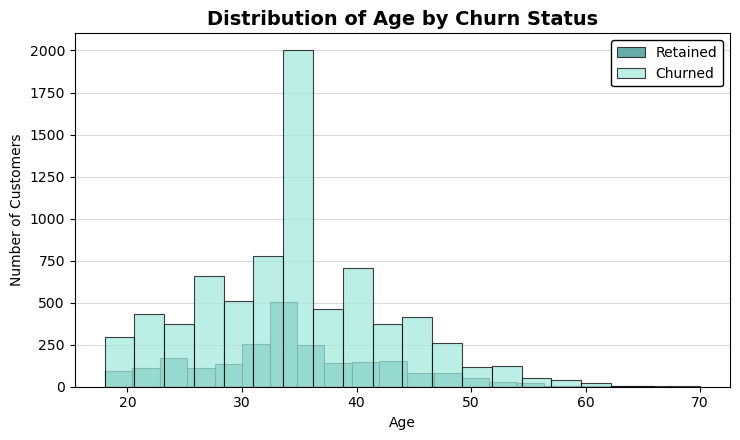

In [168]:
retained_age = df_work[df_work.Churn == 0]['Age']
churned_age = df_work[df_work.Churn == 1]['Age']

plt.figure(figsize=(7.5, 4.5))

plt.hist(retained_age, bins=20, alpha=0.75, label='Retained',
         color='#34908B', edgecolor='black', linewidth=0.8)
plt.hist(churned_age, bins=20, alpha=0.75, label='Churned',
         color='#A5E9DD', edgecolor='black', linewidth=0.8)

plt.title('Distribution of Age by Churn Status', fontsize=14, fontweight='bold')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.grid(axis='y', color='gray', alpha=0.3, linewidth=0.7)
plt.gca().set_axisbelow(True)  # grid behind bars

plt.legend(frameon=True, edgecolor='black', framealpha=1)

plt.tight_layout()
plt.show()

In [169]:
# The two distributions overlap almost completely and share the same shape and peak
# around age 30-34. Age doesn't separate churners from retained customers in any visible way.

<h2 style="color:#519A66;">7. Deeper Bivariate Analysis</h2>
<hr style="border: 2px solid #519A66;">

<h3 style="color:#CC3A63;">Does monthly spend vary by subscription plan?</h3>

<Figure size 700x450 with 0 Axes>

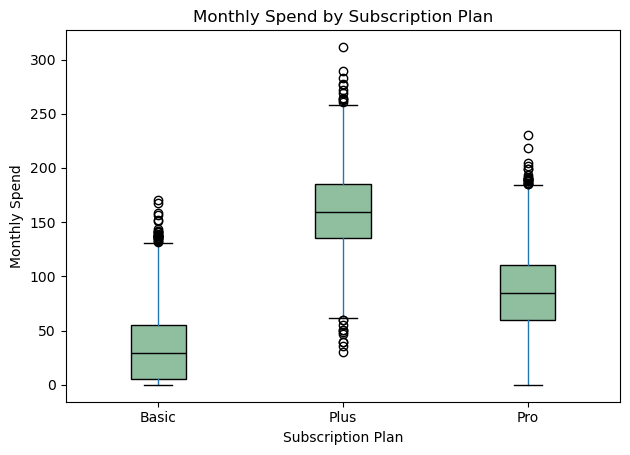

In [170]:
plt.figure(figsize=(7, 4.5))
df_work.boxplot(column='Monthly_Spend', by='Subscription_Plan', grid=False,
           patch_artist=True,
           boxprops=dict(facecolor='#8FBF9F'),
           medianprops=dict(color='black'))
plt.title('Monthly Spend by Subscription Plan')
plt.suptitle('')
plt.xlabel('Subscription Plan')
plt.ylabel('Monthly Spend')
plt.tight_layout()
plt.show()

In [171]:
# Monthly Spend differs noticeably across Subscription Plans.
# Plus has the highest median spend, while Basic has the lowest.
# Pro falls between the two plans.
# Several high-value outliers are also visible, especially in Plus and Pro.
# Overall, higher-tier plans are associated with higher monthly spending.

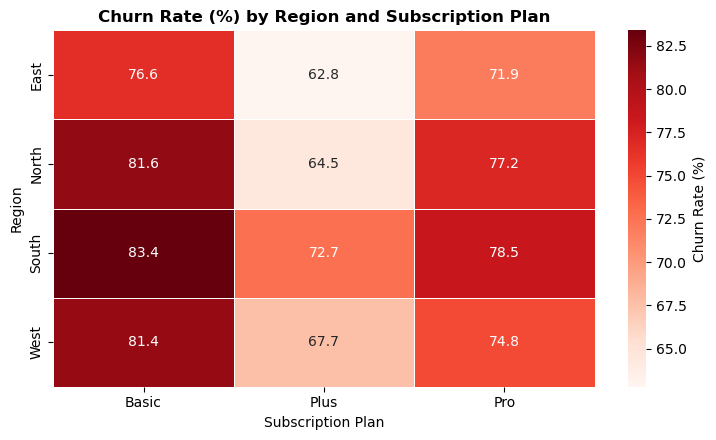

In [172]:
# Cross-tab: churn rate by Region and Subscription_Plan together
region_plan_churn = (
    df_work.groupby(['Region', 'Subscription_Plan'])['Churn']
      .mean()
      .mul(100)
      .round(1)
      .unstack()
)

plt.figure(figsize=(7.5, 4.5))
sns.heatmap(region_plan_churn, annot=True, fmt='.1f', cmap='Reds',
            linewidths=0.5, linecolor='white', cbar_kws={'label': 'Churn Rate (%)'})
plt.title('Churn Rate (%) by Region and Subscription Plan', fontsize=12, fontweight='bold')
plt.ylabel('Region')
plt.xlabel('Subscription Plan')
plt.tight_layout()
plt.show()


In [173]:
# Combining Region and Subscription Plan shows that Churn is not uniform across all groups.
# Basic customers generally have the highest churn rate across all regions,
# while Plus customers tend to have the lowest.
# The highest churn rate is observed in the South with the Basic plan (83.4%).
# The lowest churn rate is observed in the East with the Plus plan (62.8%).
# Overall, churn varies by both Region and Subscription Plan,
# making this combined analysis useful for more targeted retention strategies.

<h2 style="color:#519A66;">8. Dashboard</h2>
<hr style="border: 2px solid #519A66;">

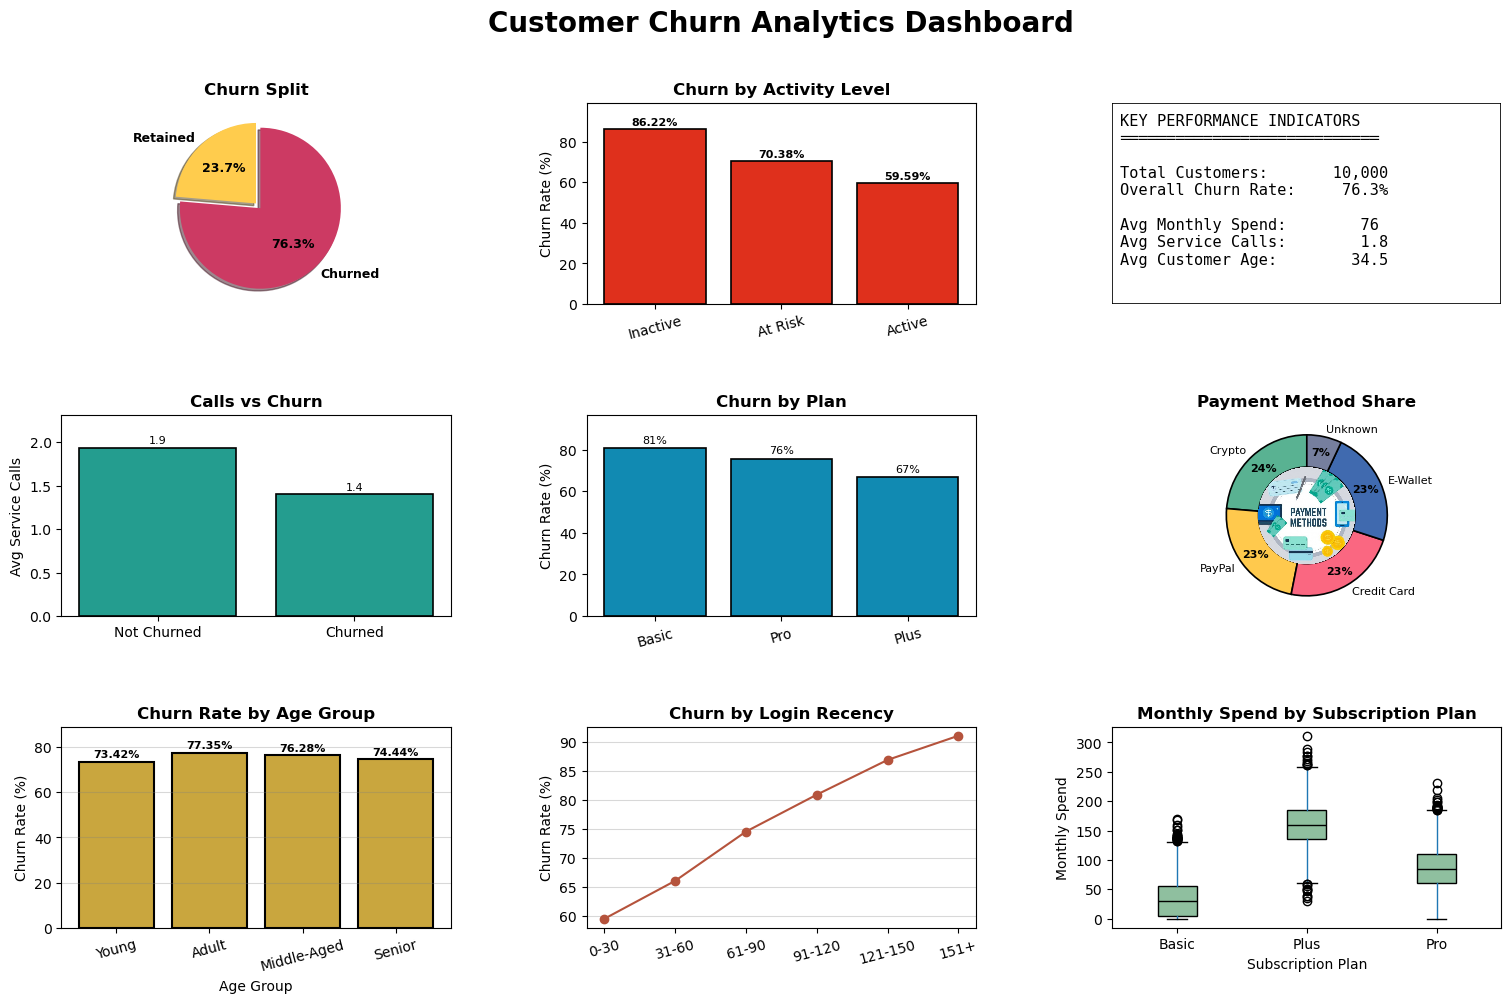

In [174]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

fig = plt.figure(figsize=(18, 11))

fig.suptitle(
    'Customer Churn Analytics Dashboard',
    fontsize=20,
    fontweight='bold',
    y=0.985
)

gs = gridspec.GridSpec(
    3, 3,
    figure=fig,
    hspace=0.55,
    wspace=0.35
)


# ------------------------------------------------------------
# [0,0] Churn Split (Pie)
# ------------------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])

churn_counts = df_work['Churn'].value_counts().sort_index()

labels = ['Retained', 'Churned']
colors = ['#FFCC4D', '#CC3A63']

explode = [
    0.08 if v == churn_counts.max() else 0
    for v in churn_counts.values
]

ax1.pie(
    churn_counts.values,
    labels=labels,
    autopct='%1.1f%%',
    colors=colors,
    startangle=90,
    explode=explode,
    shadow=True,
    textprops={
        'fontsize': 9,
        'fontweight': 'bold'
    }
)

ax1.set_title(
    'Churn Split',
    fontsize=12,
    fontweight='bold'
)


# ------------------------------------------------------------
# [0,1] Churn by Activity Level (Bar)
# ------------------------------------------------------------
ax2 = fig.add_subplot(gs[0, 1])

churn_by_activity_level = (
    df_work.groupby('Login_Activity')['Churn']
      .mean()
      .mul(100)
      .round(2)
      .sort_values(ascending=False)
)

bars2 = ax2.bar(
    churn_by_activity_level.index,
    churn_by_activity_level.values,
    color='#DF301C',
    edgecolor='black',
    linewidth=1.2
)

# Add value labels
for bar in bars2:
    height = bar.get_height()

    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f'{height:.2f}%',
        ha='center',
        va='bottom',
        fontsize=8,
        fontweight='bold'
    )

ax2.set_title(
    'Churn by Activity Level',
    fontsize=12,
    fontweight='bold'
)

ax2.set_ylabel('Churn Rate (%)')

ax2.tick_params(
    axis='x',
    rotation=15
)

ax2.set_ylim(
    0,
    max(churn_by_activity_level.values) * 1.15
)


# ------------------------------------------------------------
# [0,2] KPI Summary Panel
# ------------------------------------------------------------
ax3 = fig.add_subplot(gs[0, 2])

ax3.axis('off')

total_customers = len(df_work)

churn_rate_overall = (
    df_work['Churn'].mean() * 100
)

avg_spend = df_work['Monthly_Spend'].mean()

avg_age = df_work['Age'].mean()

avg_calls = (
    df_work['Customer_Service_Calls'].mean()
)

kpi_text = (
    "KEY PERFORMANCE INDICATORS\n"
    "════════════════════════════\n\n"
    f"Total Customers:      {total_customers:>7,}\n"
    f"Overall Churn Rate:   {churn_rate_overall:>6.1f}%\n\n"
    f"Avg Monthly Spend:  {avg_spend:>8,.0f}\n"
    f"Avg Service Calls:    {avg_calls:>7.1f}\n"
    f"Avg Customer Age:     {avg_age:>7.1f}\n"
)

ax3.text(
    0.02,
    0.95,
    kpi_text,
    fontsize=11,
    family='monospace',
    va='top',
    ha='left',
    transform=ax3.transAxes
)

ax3.add_patch(
    plt.Rectangle(
        (0, 0),
        1,
        1,
        fill=False,
        edgecolor='black',
        linewidth=1.2,
        transform=ax3.transAxes
    )
)


# ------------------------------------------------------------
# [1,0] Calls vs Churn (Bar with labels)
# ------------------------------------------------------------
ax4 = fig.add_subplot(gs[1, 0])

calls_by_churn = (
    df_work.groupby('Churn')['Customer_Service_Calls']
      .mean()
      .round(2)
      .sort_values(ascending=False)
)

bars4 = ax4.bar(
    ['Not Churned', 'Churned'],
    calls_by_churn.values,
    color='#249D8F',
    edgecolor='black',
    linewidth=1.2
)

# Add value labels
for bar in bars4:

    h = bar.get_height()

    ax4.text(
        bar.get_x() + bar.get_width() / 2,
        h + h * 0.02,
        f'{h:.1f}',
        ha='center',
        va='bottom',
        fontsize=8
    )

ax4.set_title(
    'Calls vs Churn',
    fontsize=12,
    fontweight='bold'
)

ax4.set_ylabel('Avg Service Calls')

ax4.set_ylim(
    0,
    max(calls_by_churn.values) * 1.2
)


# ------------------------------------------------------------
# [1,1] Churn by Plan (Bar with labels)
# ------------------------------------------------------------
ax5 = fig.add_subplot(gs[1, 1])

churn_by_plan = (
    df_work.groupby('Subscription_Plan')['Churn']
      .mean()
      .mul(100)
      .round(2)
      .sort_values(ascending=False)
)

bars5 = ax5.bar(
    churn_by_plan.index,
    churn_by_plan.values,
    color='#118AB2',
    edgecolor='black',
    linewidth=1.2
)

# Add value labels
for bar in bars5:

    h = bar.get_height()

    ax5.text(
        bar.get_x() + bar.get_width() / 2,
        h + h * 0.02,
        f'{h:.0f}%',
        ha='center',
        va='bottom',
        fontsize=8
    )

ax5.set_title(
    'Churn by Plan',
    fontsize=12,
    fontweight='bold'
)

ax5.set_ylabel('Churn Rate (%)')

ax5.set_ylim(
    0,
    max(churn_by_plan.values) * 1.2
)

ax5.tick_params(
    axis='x',
    rotation=15
)


# ------------------------------------------------------------
# [1,2] Payment Method Share (Donut with logo in center)
# ------------------------------------------------------------
ax6 = fig.add_subplot(gs[1, 2])

payment_counts = (
    df_work['Payment_Method']
    .value_counts()
)

wedges6, _ = ax6.pie(
    payment_counts.values,
    labels=payment_counts.index,
    startangle=90,
    colors=[
        '#59B292',
        '#FFC94D',
        '#FA6781',
        '#406AAF',
        '#767F9E'
    ],
    wedgeprops={
        'width': 0.4,
        'edgecolor': 'black',
        'linewidth': 1.2
    },
    labeldistance=1.1,
    textprops={
        'fontsize': 8
    }
)

total6 = payment_counts.sum()

# Add percentages inside donut
for wedge, value in zip(
    wedges6,
    payment_counts.values
):

    pct = value / total6 * 100

    angle = np.deg2rad(
        (wedge.theta1 + wedge.theta2) / 2
    )

    x, y = np.cos(angle), np.sin(angle)

    ax6.annotate(
        f'{pct:.0f}%',
        xy=(x * 0.8, y * 0.8),
        fontsize=8,
        fontweight='bold',
        ha='center',
        va='center'
    )


# Put payment-methods logo in donut hole
try:

    logo = Image.open(
        'payment-methods.jpg'
    ).convert('RGBA')

    size = min(logo.size)

    left = (
        logo.width - size
    ) // 2

    top = (
        logo.height - size
    ) // 2

    logo = logo.crop(
        (
            left,
            top,
            left + size,
            top + size
        )
    )

    mask = Image.new(
        'L',
        logo.size,
        0
    )

    draw = ImageDraw.Draw(mask)

    draw.ellipse(
        (
            0,
            0,
            logo.width,
            logo.height
        ),
        fill=255
    )

    logo.putalpha(mask)

    logo_array = np.array(logo)

    imagebox = OffsetImage(
        logo_array,
        zoom=0.14
    )

    ab = AnnotationBbox(
        imagebox,
        (0, 0),
        frameon=False,
        box_alignment=(0.5, 0.5)
    )

    ax6.add_artist(ab)

except FileNotFoundError:
    pass

ax6.set_title(
    'Payment Method Share',
    fontsize=12,
    fontweight='bold'
)

ax6.set_aspect('equal')


# ------------------------------------------------------------
# [2,0] Churn by Age Group (Bar with labels)
# ------------------------------------------------------------
ax7 = fig.add_subplot(gs[2, 0])

churn_by_age = (
    df_work.groupby(
        'Age_Group',
        observed=True
    )['Churn']
      .mean()
      .mul(100)
      .round(2)
)

bars7 = ax7.bar(
    churn_by_age.index.astype(str),
    churn_by_age.values,
    color='#C9A63E',
    edgecolor='black',
    linewidth=1.5
)

# Add value labels
for bar in bars7:

    height = bar.get_height()

    ax7.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f'{height:.2f}%',
        ha='center',
        va='bottom',
        fontsize=8,
        fontweight='bold'
    )

ax7.set_title(
    'Churn Rate by Age Group',
    fontsize=12,
    fontweight='bold'
)

ax7.set_xlabel('Age Group')

ax7.set_ylabel('Churn Rate (%)')

ax7.set_ylim(
    0,
    max(churn_by_age.values) * 1.15
)

ax7.tick_params(
    axis='x',
    rotation=15
)

ax7.grid(
    axis='y',
    color='gray',
    alpha=0.3
)


# ------------------------------------------------------------
# [2,1] Churn by Login Recency (Line)
# ------------------------------------------------------------
ax8 = fig.add_subplot(gs[2, 1])

bins = [
    -1,
    30,
    60,
    90,
    120,
    150,
    200
]

day_labels = [
    '0-30',
    '31-60',
    '61-90',
    '91-120',
    '121-150',
    '151+'
]

df_work['days_bucket'] = pd.cut(
    df_work['Days_Since_Last_Login'],
    bins=bins,
    labels=day_labels
)

churn_by_days = (
    df_work.groupby(
        'days_bucket',
        observed=True
    )['Churn']
      .mean()
      .mul(100)
      .round(2)
)

ax8.plot(
    churn_by_days.index,
    churn_by_days.values,
    marker='o',
    color='#B5533C'
)

ax8.set_title(
    'Churn by Login Recency',
    fontsize=12,
    fontweight='bold'
)

ax8.set_ylabel(
    'Churn Rate (%)'
)

ax8.tick_params(
    axis='x',
    rotation=15
)

ax8.grid(
    axis='y',
    color='gray',
    alpha=0.3
)


# ------------------------------------------------------------
# [2,2] Monthly Spend by Subscription Plan (Boxplot)
# ------------------------------------------------------------
ax9 = fig.add_subplot(gs[2, 2])

df_work.boxplot(
    column='Monthly_Spend',
    by='Subscription_Plan',
    grid=False,
    patch_artist=True,
    boxprops=dict(
        facecolor='#8FBF9F'
    ),
    medianprops=dict(
        color='black'
    ),
    ax=ax9
)

ax9.set_title(
    'Monthly Spend by Subscription Plan',
    fontsize=12,
    fontweight='bold'
)

ax9.set_xlabel(
    'Subscription Plan'
)

ax9.set_ylabel(
    'Monthly Spend'
)

# Remove pandas automatic title
fig.suptitle(
    'Customer Churn Analytics Dashboard',
    fontsize=20,
    fontweight='bold',
    y=0.985
)

# ------------------------------------------------------------
# Final Layout
# ------------------------------------------------------------
plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.savefig(
    'churn_dashboard.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

<h2 style="color:#519A66;">9. Conclusion &amp; Recommendations</h2>
<hr style="border: 2px solid #519A66;">

### Key Insights

1. **Inactivity is the strongest churn driver.** Customers who haven't logged in for 90+ days churn at much higher rates, and `Days_Since_Last_Login` has the strongest correlation with Churn among all numeric features (confirmed by t-test).
2. **Subscription plan matters.** The Basic plan has the highest churn rate (80%) vs. Plus (67%), and this relationship is statistically significant (chi-square test).
3. **Spend and churn are inversely related.** Churned customers spend less on average (71 vs 91), and the difference is statistically significant.
4. **Region has a real, if smaller, effect.** The South region churns more than the East, and this relationship is statistically significant.
5. **Weak/no effect:** Gender and Payment_Method show no statistically significant relationship with churn - they are not useful targeting variables on their own.
6. **The dataset is imbalanced** (76% churned vs 24% retained)

### Recommendations

- **Prioritize win-back campaigns for inactive customers**, especially those past the 90-day login mark - this is the single clearest churn signal in the data.
- **Investigate the Basic plan experience.** Its churn rate is well above other plans; consider whether pricing, features, or onboarding are driving customers away.
- **Target the South region** with retention offers, and look into region-specific causes (support quality, competition, pricing perception).
- **Use spend level as an early-warning signal** - customers with declining spend could be flagged for proactive outreach before they churn.
- **Don't invest retention budget based on Gender or Payment_Method** - the data doesn't support these as meaningful churn predictors.